The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


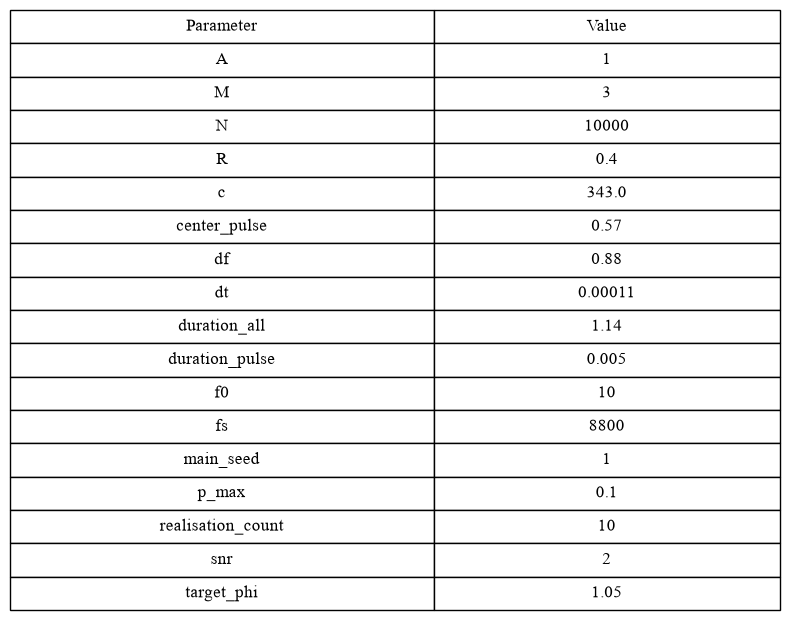

In [ ]:
"""В данном модуле рассматривается приближённая модель 
без учета задержек в стиринг векторе
Сравниваются методы Бартлетта и Кейпона для оценки азимута прихода сигнала
"""
import os
import time

%load_ext autoreload
%autoreload 2

import src.experement as experement
import src.pseudospectrum as pseudospectrum
import src.configs.config as config
import src.signals as signals
import src.model as model
import src.plotting as plotting

origin_config = config.init_rng()
path = "attachment/images/report"
os.makedirs(path,exist_ok=True)

config_random = dict( # noqa: C408
                    is_CRN = False, 
                    is_random_start = True)

config_bartlett_aprox = dict(  # noqa: C408
                            pseudo_dunc=pseudospectrum.approx_bartlett,
                            signal_func = signals.sinus,
                            stat_func = experement.calculate_variance,
                            stiring_func = model.calculate_stiring_matrix,
                            **config_random
                            )
config_capon_aprox = dict(  # noqa: C408
                            pseudo_dunc=pseudospectrum.approx_capon,
                            signal_func = signals.sinus,
                            stat_func = experement.calculate_variance,
                            stiring_func = model.calculate_stiring_matrix,
                            **config_random
                            )

plotting.config_table(origin_config)

In [ ]:
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "target_phi",
    parametr_values = origin_config['phi_values'],
)        

var_bartlett_vs_phis = experement.stat_vs_params(config_params = config_parametrs1,
                                    **parametr_config,
                                    **config_bartlett_aprox)
var_cap_vs_phis = experement.stat_vs_params(config_params = config_parametrs2,
                                    **parametr_config,
                                    **config_capon_aprox)
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Source azimuth $\\varphi_0$, deg', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

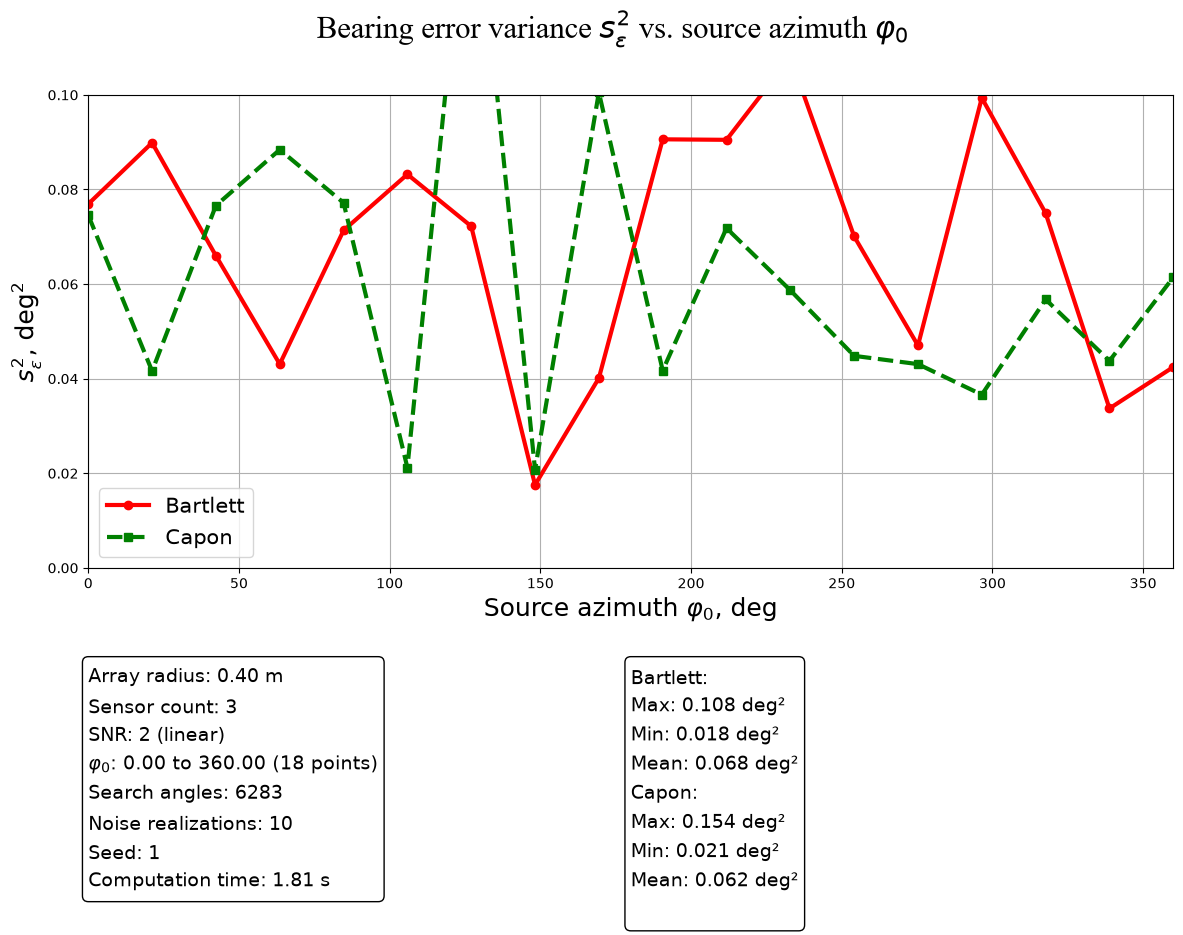

In [9]:
plotting.plot_variance_vs_param(dict_values = {"Bartlett": var_bartlett_vs_phis,
                                      "Capon": var_cap_vs_phis},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0.00*origin_config['const_radian'], 0.1*origin_config['const_radian']),
                       xlim = (0,360),
                       **parametr_config)

In [ ]:
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
start_time = time.perf_counter()
    
parametr_config = dict(  # noqa: C408
    parametr_name = "snr",
    parametr_values = origin_config['snr_values'],
)        

var_bartlett_vs_snr = experement.stat_vs_params(config_params=config_parametrs1,
                                   **parametr_config,
                                   **config_bartlett_aprox
                                   )
var_cap_vs_snr = experement.stat_vs_params(config_params=config_parametrs2,
                                   **parametr_config,
                                   **config_capon_aprox
                                   )

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='SNR (linear)', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

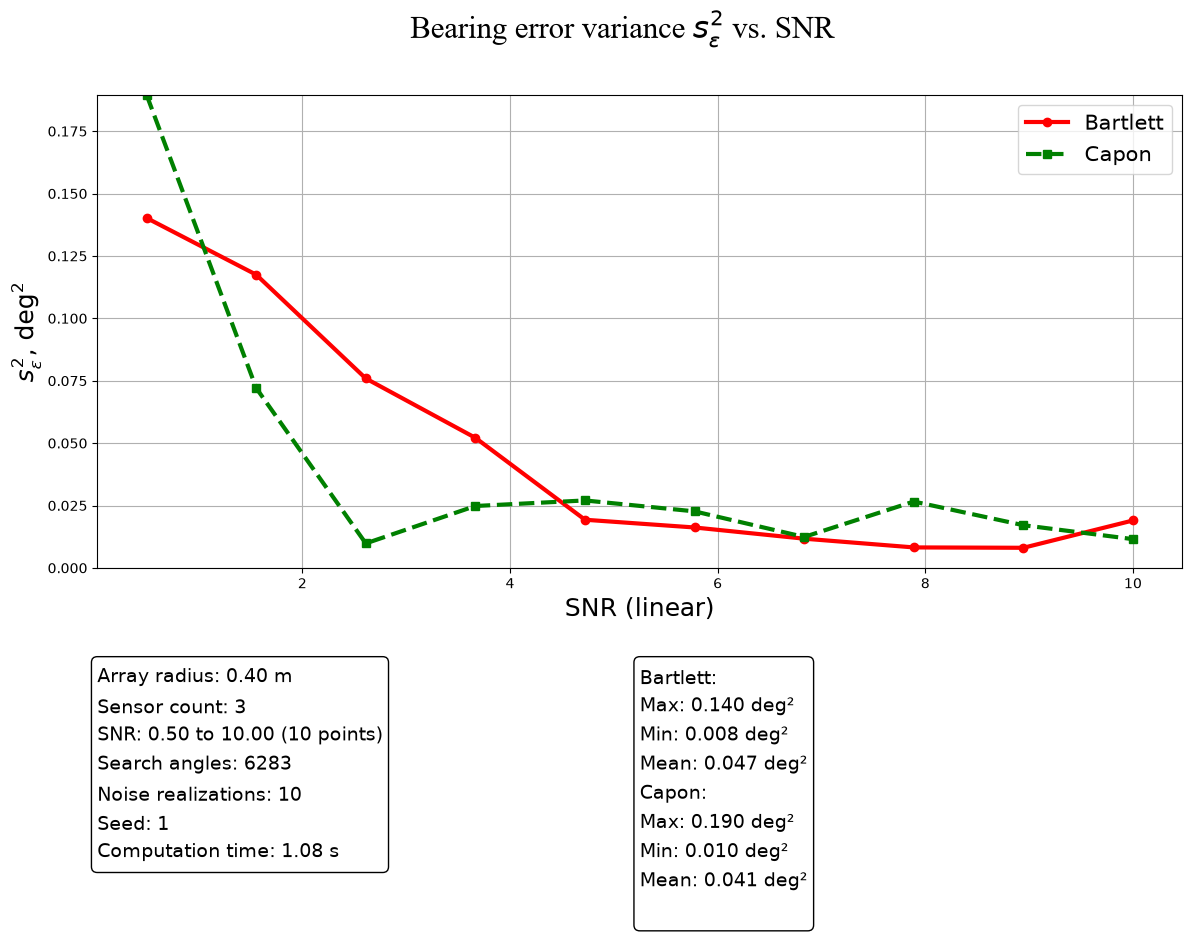

In [ ]:
plotting.plot_variance_vs_param(dict_values = {"Bartlett": var_bartlett_vs_snr,
                                      "Capon": var_cap_vs_snr},
                       config_params = origin_config.copy(),
                       parametr_values = origin_config['snr_values'],
                       parametr_name = "snr",
                       delta_time = delta_time,
                       ylim = (0, max(max(var_bartlett_vs_snr),max(var_cap_vs_snr))))

In [ ]:
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)


start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "R",
    parametr_values = origin_config['radius_values']
)
var_bartlett_vs_r = experement.stat_vs_params(config_params = config_parametrs1,
                              **parametr_config,
                              **config_bartlett_aprox)


var_cap_vs_r = experement.stat_vs_params(config_params = config_parametrs2,
                                **parametr_config,
                                **config_capon_aprox
                                )

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Array radius $R$, m', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

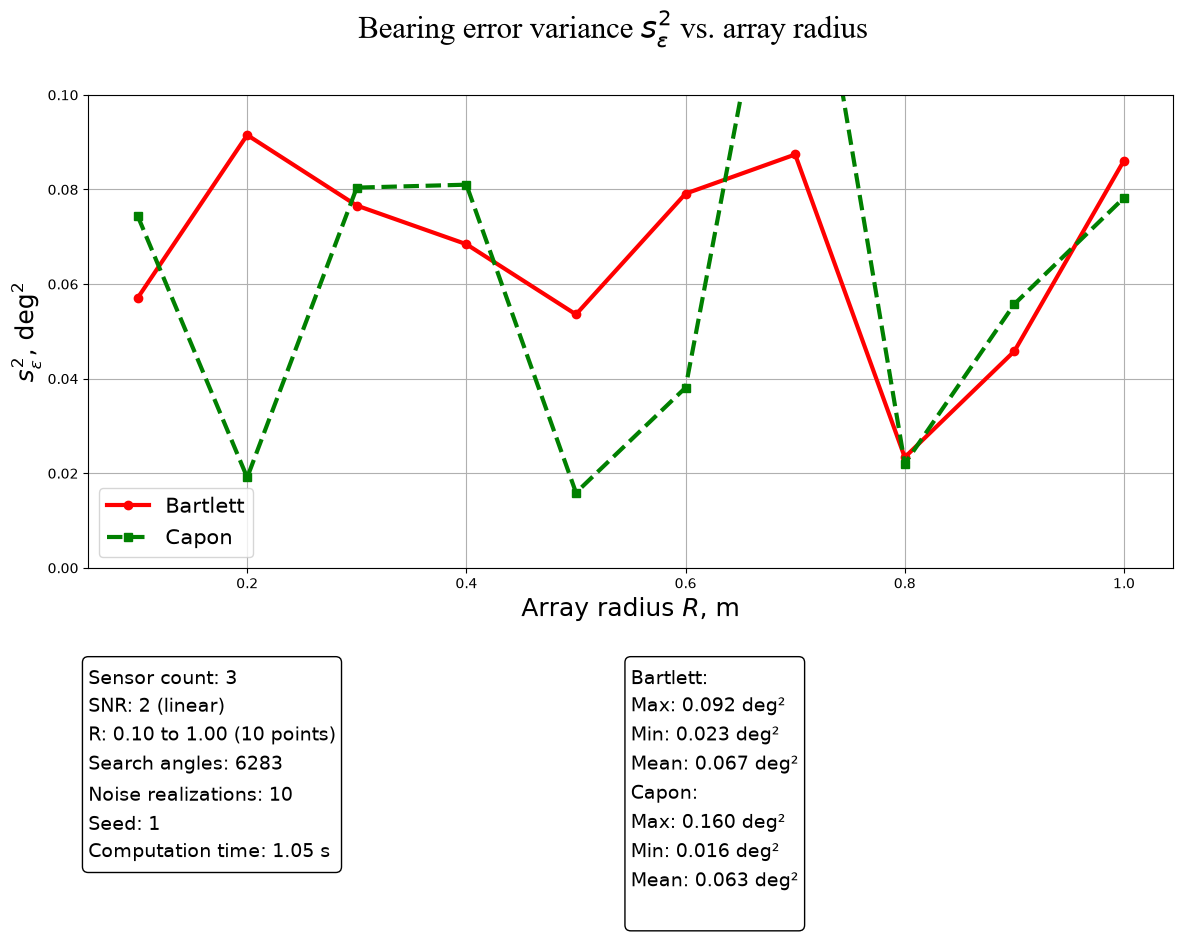

In [13]:
plotting.plot_variance_vs_param(dict_values = {"Bartlett": var_bartlett_vs_r,
                                      "Capon": var_cap_vs_r},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, 0.1*origin_config['const_radian']),
                       **parametr_config)

In [ ]:
config_parametrs1 = config.restart_rng(origin_config)
config_parametrs2 = config.restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "M",
    parametr_values = origin_config['sensor_values']
)    

var_bartlett_vs_m = experement.stat_vs_params(config_params = config_parametrs1,
                                 **parametr_config,
                                 **config_bartlett_aprox)


var_cap_vs_m = experement.stat_vs_params(config_params = config_parametrs2,
                             **parametr_config,
                             **config_capon_aprox)

end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Sensor count $M$', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

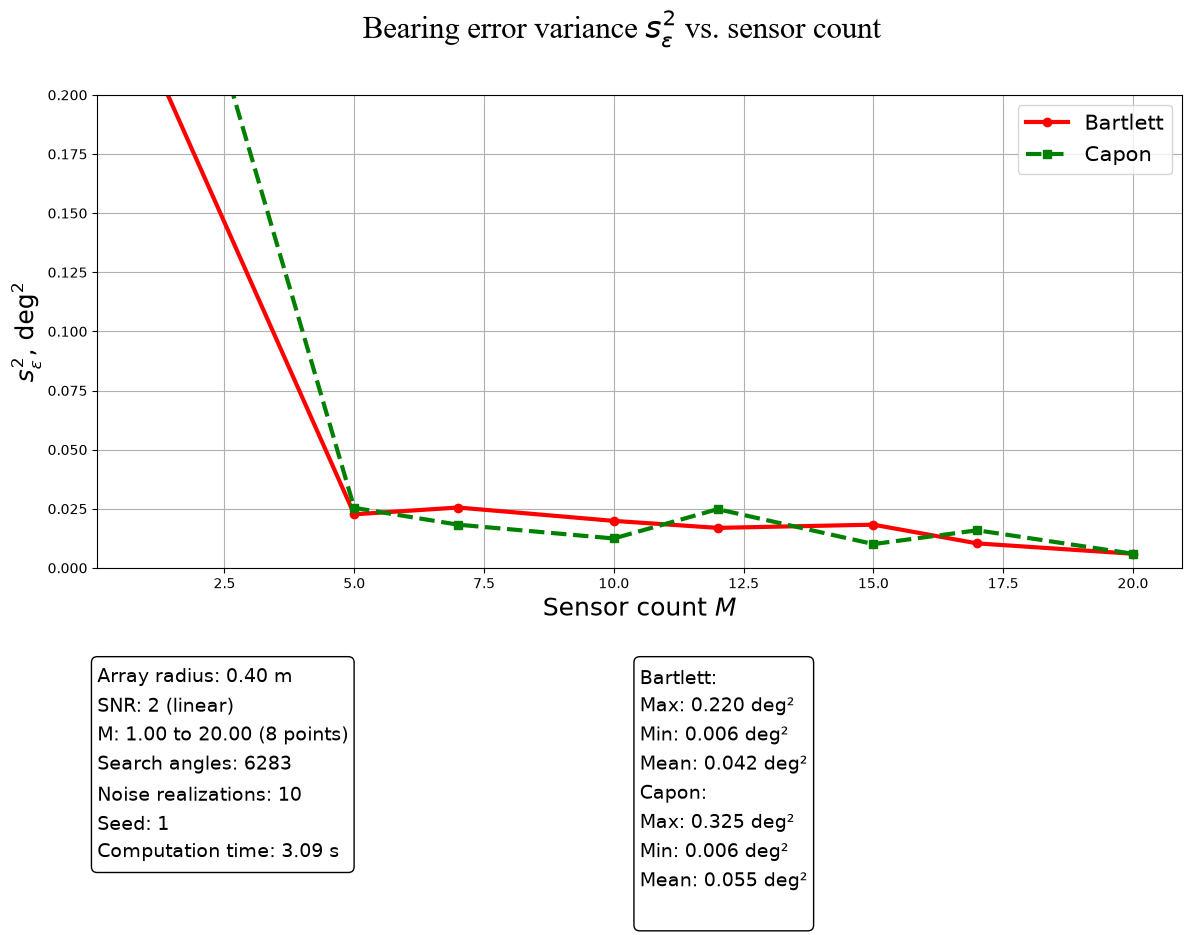

In [15]:
plotting.plot_variance_vs_param(dict_values = {"Bartlett": var_bartlett_vs_m,
                                      "Capon": var_cap_vs_m},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, 0.2*origin_config['const_radian']),
                       **parametr_config)